In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
from Moire_v2 import Moire as Moire_single
import utils

plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

In [4]:
sys = Moire(theta_deg=1.0, psi_deg=58.0, V=20, n_shells=8)

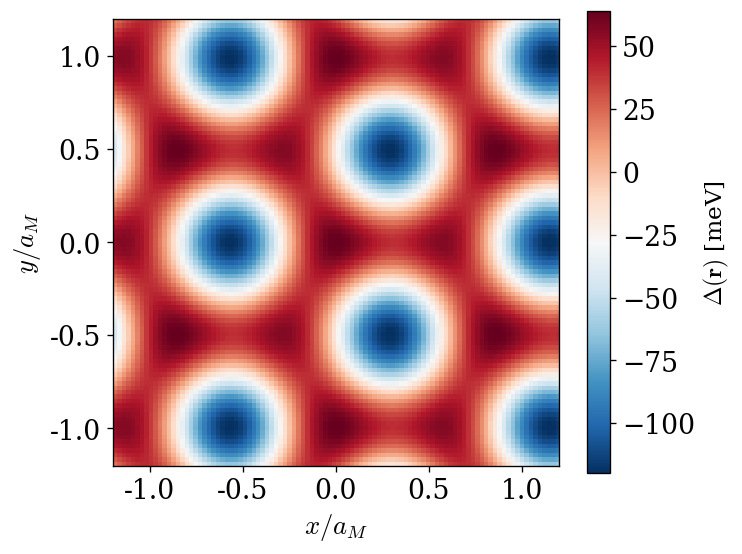

In [5]:
fig, ax = plt.subplots()
scale = 1.2
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=100)
#sys.plot_triangular_lattice(ax, extent)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta(\mathbf{r})$ [meV]", fontsize=14)

aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
#sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

### Joint Wannierization

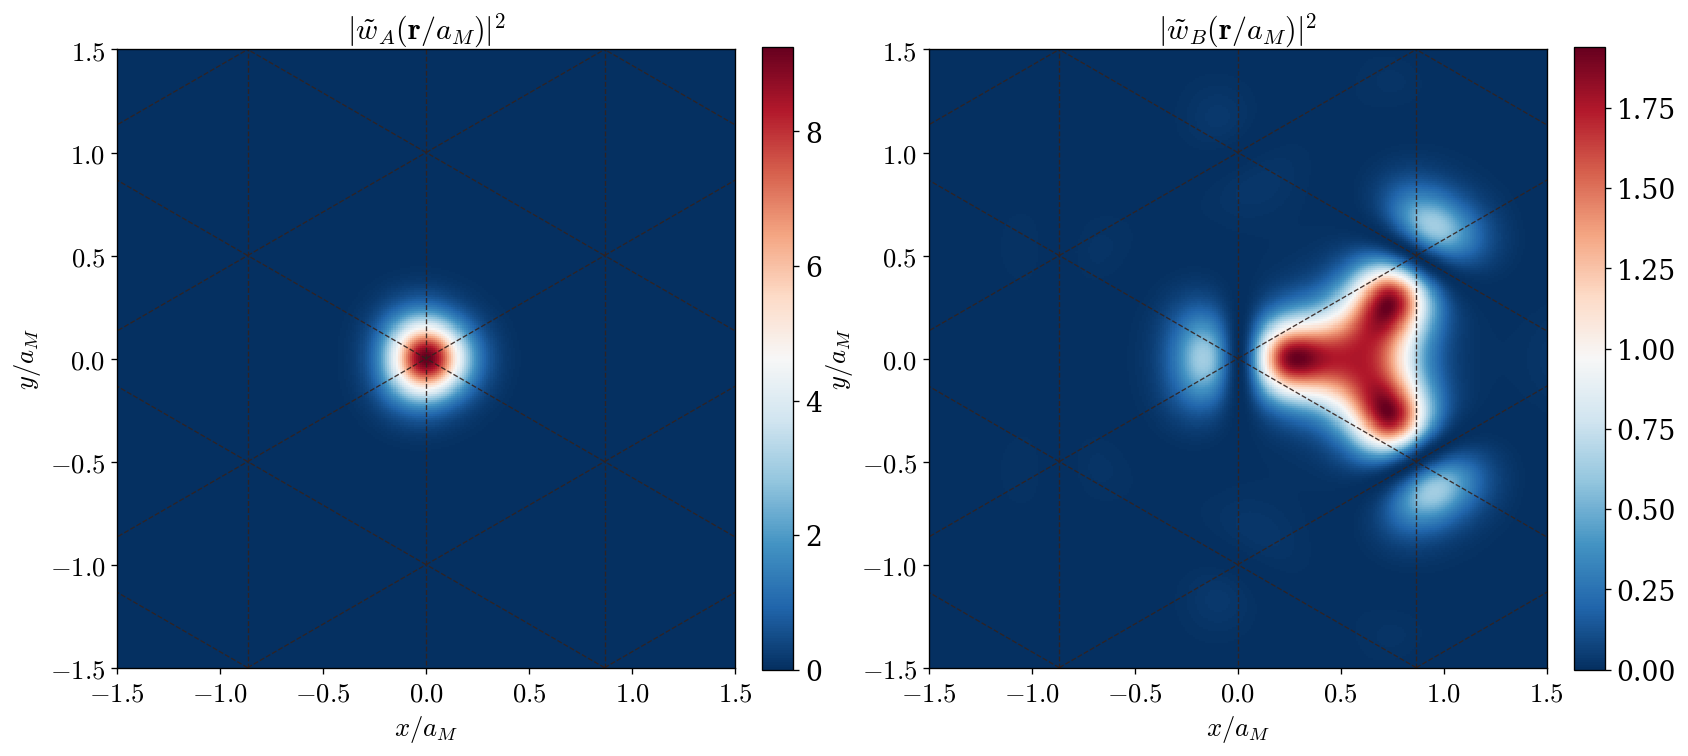

In [30]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$|\tilde{w}_A(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|\tilde{w}_B(\mathbf{r}/a_M)|^2$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_joint.pdf", dpi=300, bbox_inches='tight')

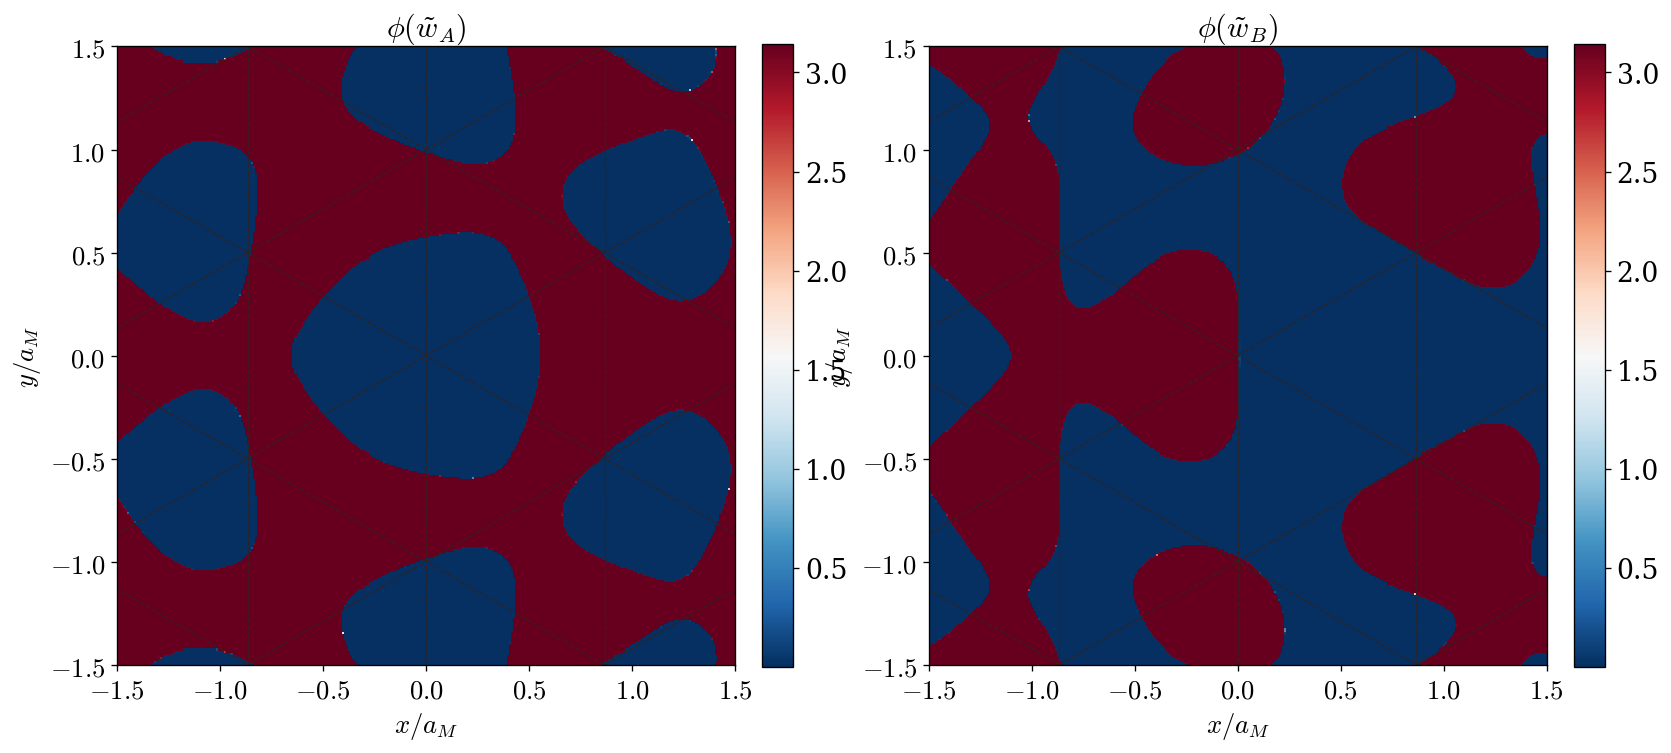

In [50]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(16, 8))

ax[0].set_title(r"$\phi(\tilde{w}_A)$", fontsize=18)
ax[0].set_xlabel(r'$x/a_M$', fontsize=16)
ax[0].set_ylabel(r'$y/a_M$', fontsize=16)

aM_i = sys.aM
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[0].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[0].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))

extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction_phase(ax[0], wannier1, extent, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$\phi(\tilde{w}_B)$", fontsize=18)
ax[1].set_xlabel(r'$x/a_M$', fontsize=16)
ax[1].set_ylabel(r'$y/a_M$', fontsize=16)
ax[1].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'${val/L:.1f}$'))
ax[1].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax[1].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction_phase(ax[1], wannier2, extent, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_joint.pdf", dpi=300, bbox_inches='tight')

In [33]:
scale = 10
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 300
Ny = 300

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]

fun_one = lambda xx, yy: 1
print("Norm1: ", sys.integrate_wannier(fun_one, wannier1, X, Y, k_points))
print("Norm2: ", sys.integrate_wannier(fun_one, wannier2, X, Y, k_points))

Norm1:  0.9999223730538827
Norm2:  0.9978764108754927


### Hopping integral

In [ ]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=20.0, n_shells=12)
sys_single = Moire_single(theta_deg=2.0, psi_deg=26.0, V=20.0, n_shells=12)
psis = np.linspace(0, 120, 11)
tAA = []
tAB = []
tBB = []
t1_single = []

scale = 4.0

Nx = 50
Ny = 50

for p in tqdm(psis):
    sys.psi_deg = p
    sys_single.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    tAA.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=1))
    tAB.append(sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=1))
    tBB.append(sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=1))

    ## Trial functions centers
    RA = np.zeros(2)
    v2 = sys.a1.copy()
    v2[1] = - v2[1]
    RB = (sys.a1 + v2) / 3
    ##

    if p > 60:
            Rshift = RB
    else:
        Rshift = np.zeros(2)
        
    t1_single.append(sys_single.hopping_integral(X, Y, k_points, order=1, trial_center=Rshift))

  0%|          | 0/11 [00:00<?, ?it/s]

100%|██████████| 11/11 [09:38<00:00, 52.62s/it]


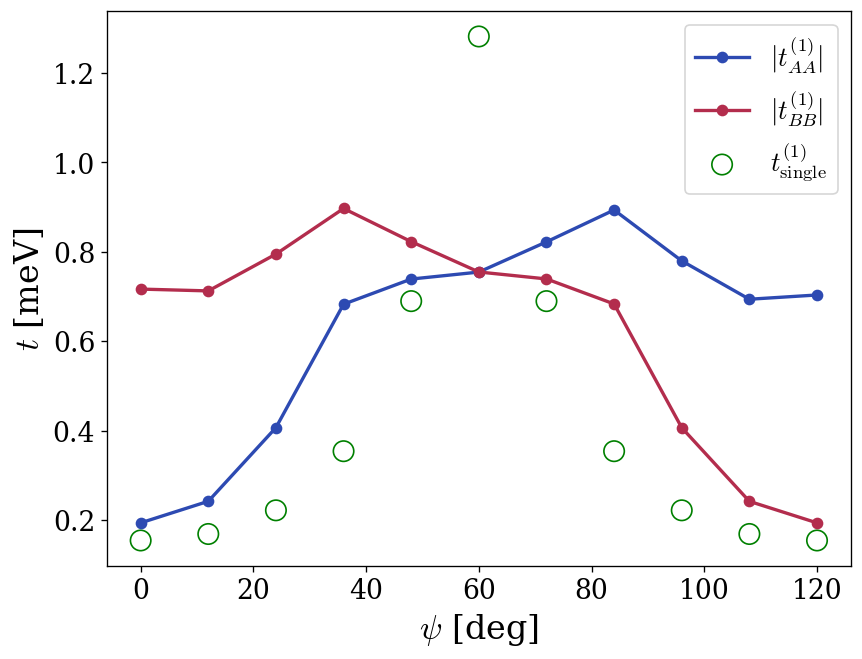

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax.plot(psis, np.abs(tAA), marker="o", label=r"$|t_{AA}^{(1)}|$", color=cols[0])
ax.plot(psis, np.abs(tBB), marker="o", label=r"$|t_{BB}^{(1)}|$", color=cols[2])
ax.scatter(psis, t1_single, facecolors='none', edgecolors='green', s=150, marker="o",
              label=r"$t_{\text{single}}^{(1)}$", color=cols[2])
ax.set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax.set_ylabel(r"$t$ [meV]", fontsize=20)
ax.legend(fontsize=16)

# ax[1].plot(psis, tAB, marker="o", label=r"$t_{AB}^{(1)}$", color=cols[1])
# ax[1].set_xlabel(r"$\psi$ [deg]", fontsize=20)
# ax[1].legend(fontsize=16)

In [34]:
sys.theta_deg = 2.0
psis = np.linspace(0, 120, 21)
UAA0 = []
UBB0 = []
UAB0 = []
UAA1 = []
UBB1 = []
UAB1 = []

scale = 4.0

Nx = 50
Ny = 50

for p in tqdm(psis):
    sys.psi_deg = p
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    
    UAA0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=0) )
    UBB0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=0) )
    UAB0.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=0) )
    UAA1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1) )
    UBB1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=1) )
    UAB1.append( sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=2) )

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [04:47<00:00, 13.68s/it]


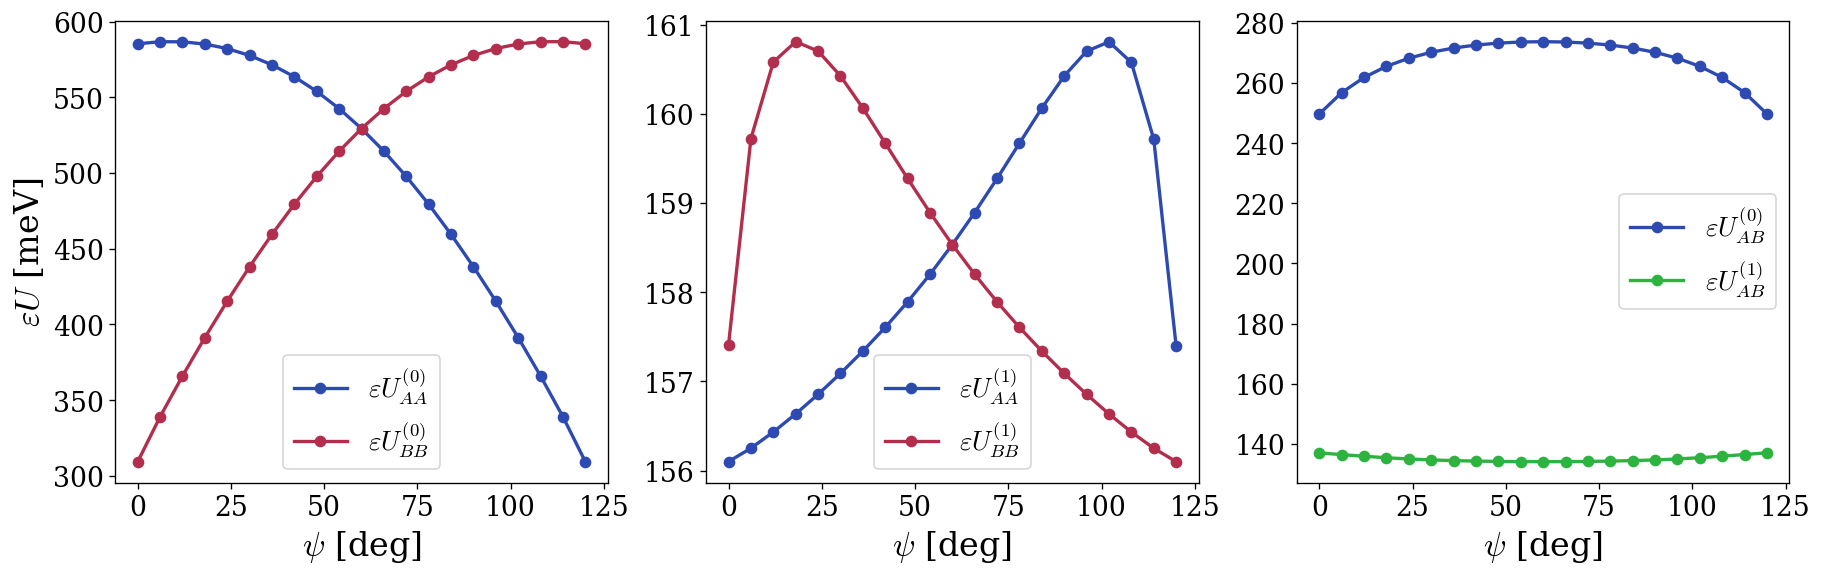

In [65]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

cols = ["#2D4AB2", "#2DB340", "#B32D4D"]

ax[0].plot(psis, UAA0, marker="o", label=r"$\varepsilon U_{AA}^{(0)}$", color=cols[0])
ax[0].plot(psis, UBB0, marker="o", label=r"$\varepsilon U_{BB}^{(0)}$", color=cols[2])
ax[0].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[0].set_ylabel(r"$\varepsilon U$ [meV]", fontsize=20)
ax[0].legend(fontsize=16)

ax[1].plot(psis, UAA1, marker="o", label=r"$\varepsilon U_{AA}^{(1)}$", color=cols[0])
ax[1].plot(psis, UBB1, marker="o", label=r"$\varepsilon U_{BB}^{(1)}$", color=cols[2])
ax[1].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[1].legend(fontsize=16)

ax[2].plot(psis, UAB0, marker="o", label=r"$\varepsilon U_{AB}^{(0)}$", color=cols[0])
ax[2].plot(psis, UAB1, marker="o", label=r"$\varepsilon U_{AB}^{(1)}$", color=cols[1])
ax[2].set_xlabel(r"$\psi$ [deg]", fontsize=20)
ax[2].legend(fontsize=16)

### Reconstructing bands

In [40]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)


scale = 4.0
Nx = 50
Ny = 50
k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

tAA0 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=np.zeros(2))
tAB0 = sys.hopping_integral(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=np.zeros(2))
tBA0 = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="A", order=0, Rshift=np.zeros(2))
tBB0 = sys.hopping_integral(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=np.zeros(2))

# onsite
T0 = np.array([[tAA0, tAB0],
               [tBA0, tBB0]], dtype=complex)


hubbard_data = {
    "system": {
        "theta [deg]": sys.theta_deg,
        "psi [deg]": sys.psi_deg,
        "V [meV]": sys.V,
        "shells": sys.n_shells,
    },
    "hopping": {
        "onsite": {
            "R": [np.zeros(2)],
            "T": [T0],
        },

        "first_nn": {
            "R": [],
            "T": [],
        },

        "second_nn": {
            "R": [],
            "T": [],
        },

        "third_nn": {
            "R": [],
            "T": [],
        }
    }
}

# nearest neighbour matrices
Tnn = []

first_nn = [sys.a1, sys.a2, sys.a2 - sys.a1]
second_nn = [2 * sys.a1 - sys.a2, sys.a1 + sys.a2, 2 * sys.a2 - sys.a1]
third_nn = [2 * sys.a1, 2 * sys.a2, 2 * sys.a2 - 2 * sys.a1]

Rs = first_nn + second_nn + third_nn
neighbours = [1, 1, 1, 2, 2, 2, 3, 3, 3]
R_reduced = [sys.a1, 2 * sys.a1 - sys.a2]

for R, nn in zip(Rs, neighbours):
    tAA = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="A",
        sublattice2="A",
        order=1,
        Rshift=R
    )

    tAB = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="A",
        sublattice2="B",
        order=1,
        Rshift=R
    )

    tBA = sys.hopping_integral(
            X, Y, k_points,
            sublattice1="B",
            sublattice2="A",
            order=1,
            Rshift=R
        )

    tBB = sys.hopping_integral(
        X, Y, k_points,
        sublattice1="B",
        sublattice2="B",
        order=1,
        Rshift=R
    )

    T = np.array([[tAA, tAB],
                  [tBA, tBB]], dtype=complex)

    hubbard_data["hopping"][f"first_nn" if nn == 1 else f"second_nn" if nn == 2 else f"third_nn"]["R"].append(R)
    hubbard_data["hopping"][f"first_nn" if nn == 1 else f"second_nn" if nn == 2 else f"third_nn"]["T"].append(T)
    Tnn.append(T)

def Hk_all(k_points, T0, Rs, Tnn):
    H = np.broadcast_to(T0, (len(k_points), 2, 2)).copy()

    for R, T in zip(Rs, Tnn):
        phase = np.exp(1j * k_points @ R)

        H += phase[:, None, None] * T
        H += phase.conj()[:, None, None] * T.conj().T

    return H

In [43]:
hubbard_data["coulomb_interactions"] = {
        "onsite": {},

        "first_nn": {},

        "second_nn": {},}

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

R0 = np.zeros(2)
R1 = sys.a1
R2 = 2 * sys.a1 - sys.a2

UAA0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=0, Rshift=R0)
UBB0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=0, Rshift=R0)
UAB0 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=0, Rshift=R0)
UAA1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="A", order=1, Rshift=R1)
UBB1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="B", sublattice2="B", order=1, Rshift=R1)
UAB1 = sys.nearest_neighbour_interaction(X, Y, k_points, sublattice1="A", sublattice2="B", order=1, Rshift=R1)

hubbard_data["coulomb_interactions"]["onsite"]["UAA"] = UAA0
hubbard_data["coulomb_interactions"]["onsite"]["UBB"] = UBB0
hubbard_data["coulomb_interactions"]["onsite"]["UAB"] = UAB0
hubbard_data["coulomb_interactions"]["first_nn"]["UAA"] = UAA1
hubbard_data["coulomb_interactions"]["first_nn"]["UBB"] = UBB1
hubbard_data["coulomb_interactions"]["first_nn"]["UAB"] = UAB1

In [ ]:
import yaml
import numpy as np

def convert_for_yaml(obj):
    if isinstance(obj, np.ndarray):
        return convert_for_yaml(obj.tolist())

    if isinstance(obj, dict):
        return {
            k: convert_for_yaml(v)
            for k, v in obj.items()
        }

    if isinstance(obj, (list, tuple)):
        return [convert_for_yaml(v) for v in obj]

    if isinstance(obj, complex):
        return f"{obj.real:.3f}{obj.imag:+.3f}j"

    if isinstance(obj, np.generic):
        return obj.item()

    return obj



with open("data/honeycomb_hubbard_theta"+str(sys.theta_deg)+"_psi"+str(sys.psi_deg)+"_V"+str(sys.V)+".yaml", "w") as f:
    yaml.safe_dump(
        convert_for_yaml(hubbard_data),
        f,
        sort_keys=False,
        default_flow_style=None
    )

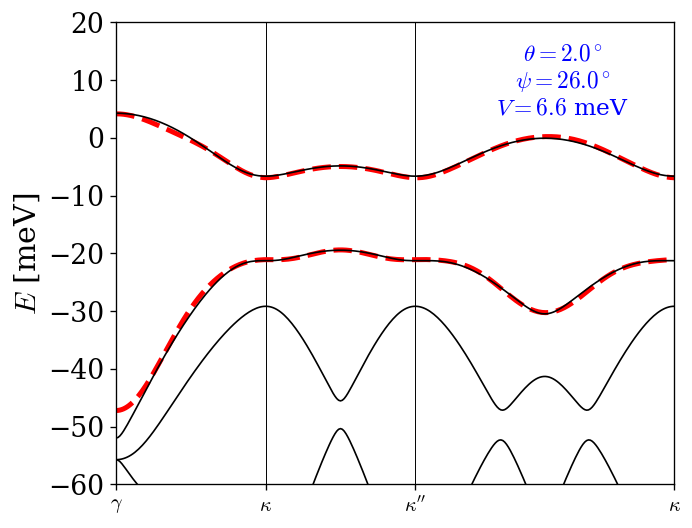

In [44]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
H = Hk_all(kpath, T0, Rs, Tnn)
energies, vectors = np.linalg.eigh(H)
energies = energies[:, ::-1]

fig, ax = plt.subplots()
sys.plot_bands(ax, energies, kdist, ticks, max_bands=2, linestyle="--", lw=3, color="red")

## ED Bands
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4, lw=1)

plt.ylim([-60, 20])
plt.text(0.8, 0.8, rf"$\theta = {sys.theta_deg:.1f}^\circ$" "\n"
    rf"$\psi = {sys.psi_deg:.1f}^\circ$" "\n"
    rf"$V = {sys.V:.1f}$ meV", 
    transform=ax.transAxes, fontsize=14, ha="center", color="blue")
plt.savefig("data/honeycomb_fit_theta"+str(sys.theta_deg)+"_psi"+str(sys.psi_deg)+"_V"+str(sys.V)+".pdf", dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)

### Single band

In [ ]:
sys = Moire_single(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=10)

scale = 4.0
Nx = 70
Ny = 70
k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

t0 = sys.hopping_integral(X, Y, k_points, order=0, Rshift=np.zeros(2))

# onsite
T0 = t0

# nearest neighbour matrices
Tnn = []

first_nn = [sys.a1, sys.a2, sys.a2 - sys.a1]
second_nn = [2 * sys.a1 - sys.a2, sys.a1 + sys.a2, 2 * sys.a2 - sys.a1]
third_nn = [2 * sys.a1, 2 * sys.a2, 2 * sys.a2 - 2 * sys.a1]

Rs = first_nn + second_nn + third_nn

for R in Rs:
    t = sys.hopping_integral(
        X, Y, k_points,
        order=1,
        Rshift=R
    )

    T = t

    Tnn.append(T)

def Hk_all(k_points, T0, Rs, Tnn):
    H = np.full(len(k_points), T0, dtype=complex)

    for R, t in zip(Rs, Tnn):
        phase = np.exp(1j * (k_points @ R))
        H += phase * t
        H += phase.conj() * np.conj(t)

    return H

/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0.8, 0.8, '$\\theta = 2.0^\\circ$\n$\\psi = 30.0^\\circ$\n$V = 6.6$ meV')

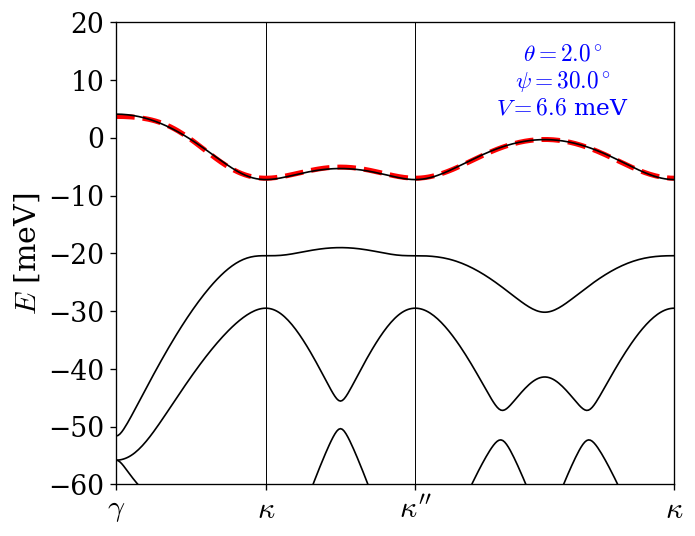

In [7]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
H = Hk_all(kpath, T0, Rs, Tnn)
# energies, vectors = np.linalg.eigh(H)
# energies = energies[:, ::-1]

fig, ax = plt.subplots()
sys.plot_bands(ax, H, kdist, ticks, max_bands=2, linestyle="--", lw=3, color="red")

## ED Bands
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4, lw=1)

plt.ylim([-60, 20])
plt.text(0.8, 0.8, rf"$\theta = {sys.theta_deg:.1f}^\circ$" "\n"
    rf"$\psi = {sys.psi_deg:.1f}^\circ$" "\n"
    rf"$V = {sys.V:.1f}$ meV", 
    transform=ax.transAxes, fontsize=14, ha="center", color="blue")
#plt.savefig("plots/two_bands.svg", dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)

In [139]:
print(T0)

(-1.9402809584873193-1.4881093309092723e-07j)


In [140]:
print(Tnn)

[(1.2463620488196567+1.0497575054120182e-06j), (1.24637785871652+5.166068832574336e-07j), (1.2463589896461338-1.2634860141192482e-08j), (-0.17658188761306315-6.053501579310226e-07j), (-0.17661591186517844+3.01436364516422e-07j), (-0.17664649024103957+2.7420446558847186e-07j), (-0.09527795157332578-7.420490716832073e-07j), (-0.0952464115945501-3.9944148601501586e-07j), (-0.0952553660525022+3.8343040181103176e-08j)]
